# Prithvi-EO-2.0-300M-TL · Sen1Floods11 flood-extent segmentation

This notebook runs **[ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11)**.
That is the IBM/NASA Prithvi-EO-2.0 300M foundation model (the "TL" version, which adds time and location embeddings) fine-tuned to map water and flooding in Sentinel-2 images.

| | |
|---|---|
| Architecture | Prithvi-EO-2.0 ViT-L encoder (300M) + UperNet decoder, 319 M parameters in total |
| Input | 6 Sentinel-2 bands: Blue (B2), Green (B3), Red (B4), Narrow NIR (B8A), SWIR1 (B11), SWIR2 (B12); reflectance = DN / 10000 |
| Output | 2 classes per pixel: **0 = no water**, **1 = water / flood** |
| Training data | Sen1Floods11 hand-labelled chips (512×512 px, 11 flood events, 6 continents) |
| Licence | Apache-2.0 |

**What the notebook does:**
1. Downloads the model and the example images.
2. Loads the model with TerraTorch.
3. Runs tiled inference on a whole image.
4. Plots the results.
5. Scores them against the Sen1Floods11 hand labels.
6. Saves georeferenced GeoTIFFs.

Runtime: about 10 s per 512×512 tile on CPU and well under 1 s on a GPU. The first run also downloads about 1.3 GB.

## 1. Setup

Requirements, which match the model repo's `requirements.txt`:
```bash
pip install "terratorch==0.99.8" torch torchvision timm einops rasterio matplotlib huggingface_hub
```

In [1]:
from pathlib import Path
import time, urllib.request

import numpy as np
import torch
import yaml
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from huggingface_hub import hf_hub_download

MODEL_REPO = "ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11"
CKPT_NAME  = "Prithvi-EO-V2-300M-TL-Sen1Floods11.pt"
MODEL_DIR  = Path("hf_model")          # model files are cached here
OUT_DIR    = Path("outputs")           # predictions are written here
OUT_DIR.mkdir(exist_ok=True)

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TILE       = 512                       # Sen1Floods11 chip size; the official inference.py also uses 512
BATCH_SIZE = 4 if DEVICE.type == "cuda" else 1

# Band indices (0-based) of the 6 model bands inside a full Sentinel-2 file
#   L1C (13 bands: B1 B2 B3 B4 B5 B6 B7 B8 B8A B9 B10 B11 B12) -> B2 B3 B4 B8A B11 B12
#   L2A (12 bands, no B10)                                  -> B2 B3 B4 B8A B11 B12
S2_L1C_INDICES = [1, 2, 3, 8, 11, 12]
S2_L2A_INDICES = [1, 2, 3, 8, 10, 11]
MODEL_BANDS    = ["BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"]

print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.6.0+cu124


/home/tsubame/miniconda3/envs/prithvi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Download the model and example data

The model repo ships three Sen1Floods11 example scenes (Sentinel-2 L1C, 13 bands). Their hand-drawn flood labels come from the public
[Sen1Floods11 bucket](https://github.com/cloudtostreet/Sen1Floods11) (`-1` = no data/cloud, `0` = no water, `1` = water). The labels are only used for scoring.

In [2]:
config_path = hf_hub_download(MODEL_REPO, "config.yaml", local_dir=MODEL_DIR)
ckpt_path   = hf_hub_download(MODEL_REPO, CKPT_NAME, local_dir=MODEL_DIR)

EXAMPLES = ["India_900498", "Spain_7370579", "USA_430764"]
LABEL_URL = ("https://storage.googleapis.com/sen1floods11/v1.1/data/flood_events/"
             "HandLabeled/LabelHand/{name}_LabelHand.tif")

image_paths, label_paths = {}, {}
for name in EXAMPLES:
    image_paths[name] = Path(hf_hub_download(MODEL_REPO, f"examples/{name}_S2Hand.tif", local_dir=MODEL_DIR))
    label_file = MODEL_DIR / "labels" / f"{name}_LabelHand.tif"
    if not label_file.exists():
        label_file.parent.mkdir(parents=True, exist_ok=True)
        try:
            urllib.request.urlretrieve(LABEL_URL.format(name=name), label_file)
        except Exception as e:                       # labels are optional
            print(f"could not download label for {name}: {e}")
            continue
    label_paths[name] = label_file

print("checkpoint:", ckpt_path)
print("images:", list(image_paths))
print("labels:", list(label_paths))

checkpoint: /home/tsubame/deeplearning/dimer_model_test/flood_segmentation_test/hf_model/Prithvi-EO-V2-300M-TL-Sen1Floods11.pt
images: ['India_900498', 'Spain_7370579', 'USA_430764']
labels: ['India_900498', 'Spain_7370579', 'USA_430764']


## 3. Load the model

`config.yaml` is the TerraTorch/Lightning training config. Two adjustments make loading for inference faster:

- **`backbone_pretrained: false`:** otherwise TerraTorch first downloads the 1.2 GB *pre-training* backbone. Those weights would be overwritten straight away by the fine-tuned checkpoint.
- **CPU precision:** the config asks for `16-mixed` precision, which is GPU-only. We call the model directly in float32, so this setting doesn't matter here.

`LightningInferenceModel` also builds the datamodule, which holds the per-band normalisation (mean/std) used during training.

In [3]:
from terratorch.cli_tools import LightningInferenceModel

cfg = yaml.safe_load(open(config_path))
cfg["model"]["init_args"]["model_args"]["backbone_pretrained"] = False
inference_config = MODEL_DIR / "config_inference.yaml"
yaml.safe_dump(cfg, open(inference_config, "w"), sort_keys=False)

t0 = time.time()
lightning_model = LightningInferenceModel.from_config(str(inference_config), ckpt_path)
model = lightning_model.model.to(DEVICE).eval()
datamodule = lightning_model.datamodule
print(f"loaded in {time.time() - t0:.0f} s | {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

norm = datamodule.aug.augs[0]                       # kornia Normalize used in training
print("band means:", [round(v, 4) for v in norm.flags["mean"].flatten().tolist()])
print("band stds: ", [round(v, 4) for v in norm.flags["std"].flatten().tolist()])

INFO:albumentations.check_version:A new version of Albumentations is available: 2.0.8 (you have 1.4.10). Upgrade using: pip install --upgrade albumentations


/home/tsubame/miniconda3/envs/prithvi/lib/python3.11/site-packages/lightning/pytorch/cli.py:528: LightningCLI's args parameter is intended to run from within Python like if it were from the command line. To prevent mistakes it is not recommended to provide both args and command line arguments, got: sys.argv[1:]=['-f', '/tmp/tmpueyjz76h.json', '--HistoryManager.hist_file=:memory:'], args=['--config', 'hf_model/config_inference.yaml'].


INFO: Seed set to 0


INFO:lightning.fabric.utilities.seed:Seed set to 0


/home/tsubame/miniconda3/envs/prithvi/lib/python3.11/site-packages/lightning/pytorch/cli.py:681: `SemanticSegmentationTask.configure_optimizers` will be overridden by `MyLightningCLI.configure_optimizers`.
/home/tsubame/miniconda3/envs/prithvi/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/accelerator_connector.py:513: You passed `Trainer(accelerator='cpu', precision='16-mixed')` but AMP with fp16 is not supported on CPU. Using `precision='bf16-mixed'` instead.
INFO: Using bfloat16 Automatic Mixed Precision (AMP)


INFO:lightning.pytorch.utilities.rank_zero:Using bfloat16 Automatic Mixed Precision (AMP)


... (3 outputs left out)

INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores


INFO: HPU available: False, using: 0 HPUs


INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs


loaded in 8 s | 319.0 M parameters
band means: [0.1413, 0.138, 0.1235, 0.309, 0.2045, 0.1191]
band stds:  [0.0741, 0.0737, 0.0869, 0.118, 0.0977, 0.0766]


## 4. Read a Sentinel-2 image

The steps are:
1. Pick the 6 model bands from the 13-band file.
2. Convert digital numbers to reflectance (÷ 10000).
3. Keep the georeferencing, so the output can be saved as a GeoTIFF.

In [4]:
def read_s2(path, band_indices=S2_L1C_INDICES):
    # returns reflectance (6, H, W) float32, a valid-pixel mask (H, W) and the rasterio profile
    with rasterio.open(path) as src:
        raw = src.read().astype("float32")
        profile = src.profile.copy()
        descriptions = src.descriptions
    bands = raw[band_indices]
    valid = np.all(bands > 0, axis=0) & np.all(bands != -9999, axis=0)   # 0 / -9999 = no data
    reflectance = bands / 10000.0 if bands[:, valid].mean() > 1 else bands
    return reflectance, valid, profile, [descriptions[i] for i in band_indices]

def read_label(path):
    with rasterio.open(path) as src:
        return src.read(1).astype("int16")

name = "India_900498"
image, valid, profile, band_names = read_s2(image_paths[name])
print(name, "| shape", image.shape, "| CRS", profile["crs"], "| bands", band_names)
print("reflectance range:", float(image.min()), "-", float(image.max()), "| valid pixels: %.1f%%" % (100 * valid.mean()))

India_900498 | shape (6, 512, 512) | CRS EPSG:4326 | bands ['B2', 'B3', 'B4', 'B8A', 'B11', 'B12']
reflectance range: 0.0006000000284984708 - 0.4449999928474426 | valid pixels: 100.0%


## 5. Tiled inference

Any image size works:
1. Reflect-pad the image to a multiple of 512.
2. Cut it into 512×512 tiles.
3. Normalise each tile exactly as in training (`datamodule.test_transform` + `datamodule.aug`).
4. Run the model and stitch the tiles back together.

This is the same approach as the repo's `inference.py`, plus the water probability (softmax). The model has no "no data" class, so pixels without valid input are set to 255 in the class map.

In [5]:
NODATA_CLASS = 255

def preprocess(tile):
    # (6, H, W) reflectance -> (1, 6, H, W) normalised tensor, exactly as in training
    x = datamodule.test_transform(image=tile.transpose(1, 2, 0))
    return datamodule.aug(x)["image"]

@torch.no_grad()
def predict_flood(image, valid=None, tile=TILE, batch_size=BATCH_SIZE, threshold=0.5):
    # image: (6, H, W) reflectance. Returns class map (H, W) uint8 and water probability (H, W) float32
    C, H, W = image.shape
    pad_h, pad_w = (-H) % tile, (-W) % tile
    padded = np.pad(image, ((0, 0), (0, pad_h), (0, pad_w)), mode="reflect")
    Hp, Wp = padded.shape[1:]
    coords = [(r, c) for r in range(0, Hp, tile) for c in range(0, Wp, tile)]

    prob = np.zeros((Hp, Wp), dtype="float32")
    for i in range(0, len(coords), batch_size):
        batch_coords = coords[i:i + batch_size]
        x = torch.cat([preprocess(padded[:, r:r + tile, c:c + tile]) for r, c in batch_coords]).to(DEVICE)
        logits = model(x).output                               # (B, 2, tile, tile)
        p_water = torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy()
        for (r, c), p in zip(batch_coords, p_water):
            prob[r:r + tile, c:c + tile] = p

    prob = prob[:H, :W]
    pred = (prob >= threshold).astype("uint8")                 # threshold 0.5 == argmax
    if valid is not None:
        pred[~valid] = NODATA_CLASS
        prob[~valid] = np.nan
    return pred, prob

t0 = time.time()
pred, prob = predict_flood(image, valid)
print(f"{name}: {time.time() - t0:.1f} s | water = {100 * (pred == 1).sum() / max((pred != NODATA_CLASS).sum(), 1):.1f}% of valid pixels")

India_900498: 7.7 s | water = 47.0% of valid pixels


## 6. Visualise

- **Natural colour:** red, green and blue bands.
- **False colour:** SWIR2, NIR and red bands. Water absorbs strongly in NIR/SWIR, so it shows as dark blue or black.
- **Prediction** and **water probability:** the model's output.
- **Hand label:** shown when available. Grey marks no data or cloud.

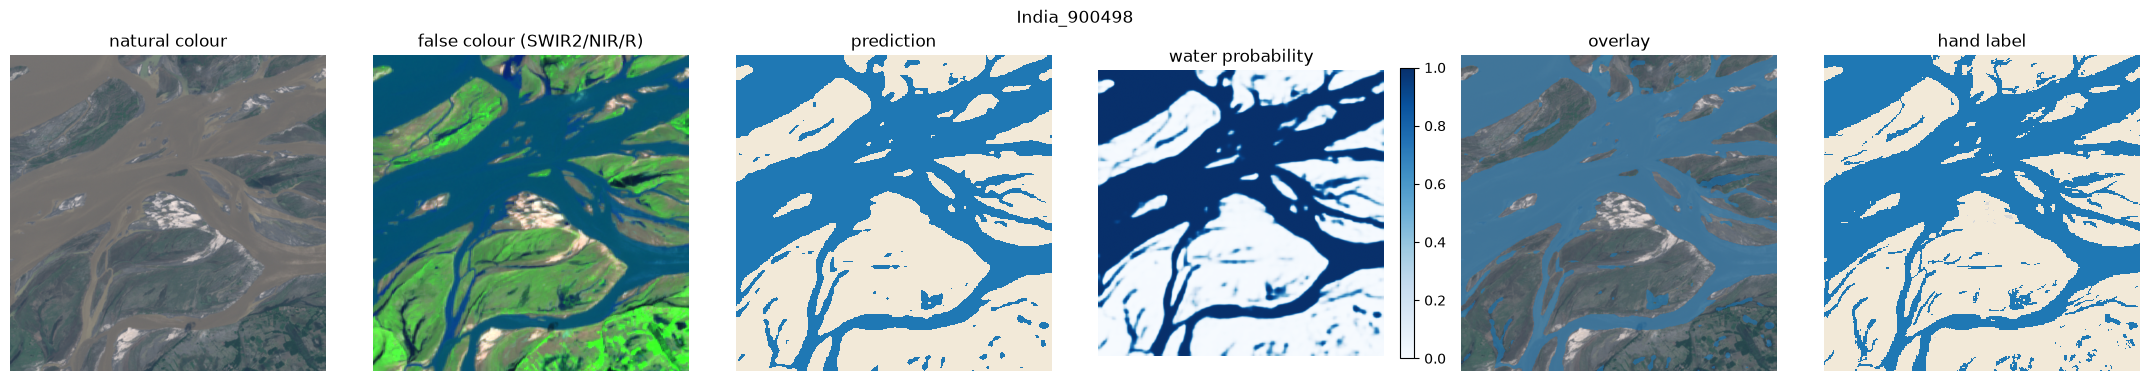

In [6]:
def stretch(rgb, valid=None):
    # percentile contrast stretch to [0, 1] for display (same idea as the official inference.py)
    rgb = rgb.copy()
    v = rgb[:, valid] if valid is not None else rgb.reshape(3, -1)
    hi = max(0.3, np.percentile(v, 99))
    return np.clip(rgb / hi, 0, 1).transpose(1, 2, 0)

WATER_CMAP = ListedColormap(["#d9d9d9", "#f2e9d8", "#1f78b4"])   # nodata, land, water

def show_class_map(ax, cls, title):
    shown = np.where(cls == NODATA_CLASS, -1, cls).astype(float)   # -1 nodata/cloud, 0 land, 1 water
    ax.imshow(shown, cmap=WATER_CMAP, vmin=-1.5, vmax=1.5, interpolation="nearest")
    ax.set_title(title)

def plot_result(name, image, valid, pred, prob, label=None):
    rgb = stretch(image[[2, 1, 0]], valid)           # RED, GREEN, BLUE
    swir = stretch(image[[5, 3, 2]], valid)          # SWIR2, NIR, RED
    overlay = rgb.copy()
    overlay[pred == 1] = 0.4 * overlay[pred == 1] + 0.6 * np.array([0.12, 0.47, 0.71])

    n = 6 if label is not None else 5
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.9))
    axes[0].imshow(rgb); axes[0].set_title("natural colour")
    axes[1].imshow(swir); axes[1].set_title("false colour (SWIR2/NIR/R)")
    show_class_map(axes[2], pred, "prediction")
    im = axes[3].imshow(prob, cmap="Blues", vmin=0, vmax=1); axes[3].set_title("water probability")
    fig.colorbar(im, ax=axes[3], fraction=0.046)
    axes[4].imshow(overlay); axes[4].set_title("overlay")
    if label is not None:
        show_class_map(axes[5], np.where(label == -1, NODATA_CLASS, label), "hand label")
    for ax in axes: ax.axis("off")
    fig.suptitle(name); fig.tight_layout(); plt.show()

label = read_label(label_paths[name]) if name in label_paths else None
plot_result(name, image, valid, pred, prob, label)

## 7. Evaluate against the hand label

Metrics use only pixels where the label is valid (label ≠ -1) and the image has data. **Water IoU** is the headline metric reported for Sen1Floods11.

In [7]:
def flood_metrics(pred, label):
    m = (label != -1) & (pred != NODATA_CLASS)
    p, t = pred[m] == 1, label[m] == 1
    tp, fp, fn, tn = np.sum(p & t), np.sum(p & ~t), np.sum(~p & t), np.sum(~p & ~t)
    iou_water = tp / max(tp + fp + fn, 1)
    iou_land = tn / max(tn + fp + fn, 1)
    return {
        "IoU water": iou_water,
        "IoU no-water": iou_land,
        "mIoU": (iou_water + iou_land) / 2,
        "F1 water": 2 * tp / max(2 * tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "accuracy": (tp + tn) / max(m.sum(), 1),
        "labelled px": int(m.sum()),
    }

if label is not None:
    for k, v in flood_metrics(pred, label).items():
        print(f"{k:>13}: {v:.3f}" if isinstance(v, float) else f"{k:>13}: {v}")

    IoU water: 0.919
 IoU no-water: 0.927
         mIoU: 0.923
     F1 water: 0.958
    precision: 0.961
       recall: 0.955
     accuracy: 0.960
  labelled px: 261992


## 8. Save GeoTIFF outputs

Two files keep the input's CRS and geotransform, so they open directly in QGIS or ArcGIS:
- `pred_<name>.tif` (uint8): 0 = no water, 1 = water, 255 = no data
- `prob_<name>.tif` (float32): water probability

In [8]:
def save_geotiff(array, path, profile, dtype, nodata):
    p = profile.copy()
    p.update(count=1, dtype=dtype, nodata=nodata, compress="lzw")
    with rasterio.open(path, "w", **p) as dst:
        dst.write(array.astype(dtype), 1)

save_geotiff(pred, OUT_DIR / f"pred_{name}.tif", profile, "uint8", NODATA_CLASS)
save_geotiff(np.nan_to_num(prob, nan=-1), OUT_DIR / f"prob_{name}.tif", profile, "float32", -1)
print(sorted(p.name for p in OUT_DIR.iterdir()))

['pred_India_900498.tif', 'prob_India_900498.tif']


## 9. Run all example scenes

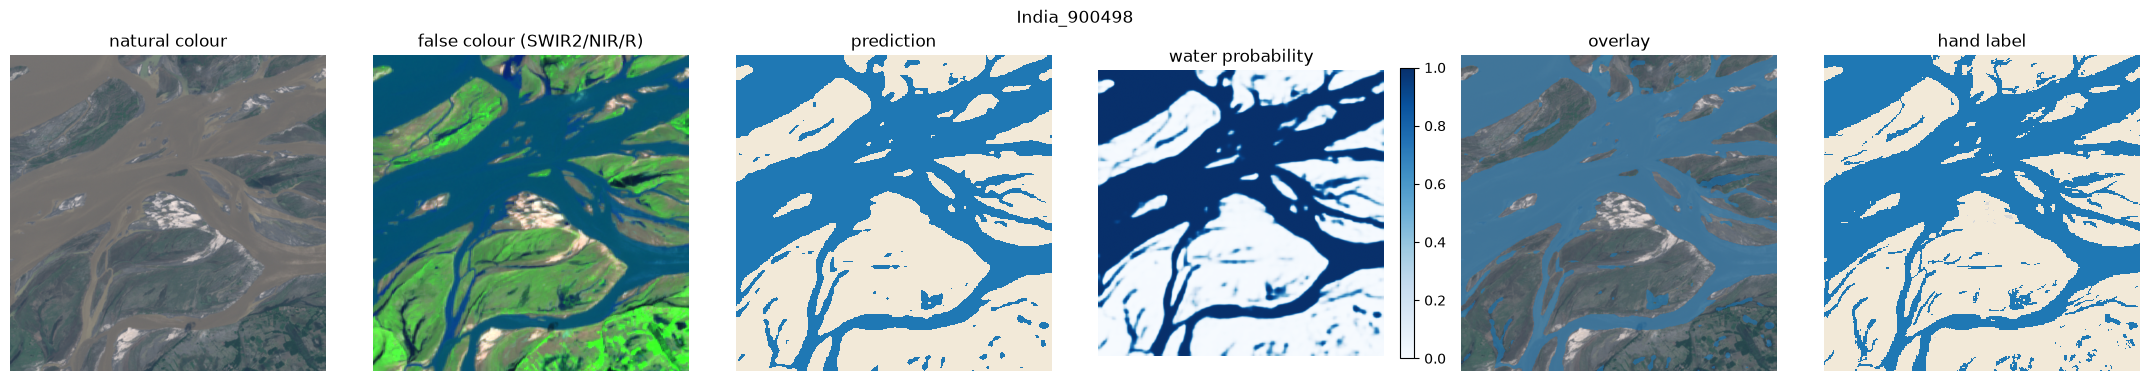

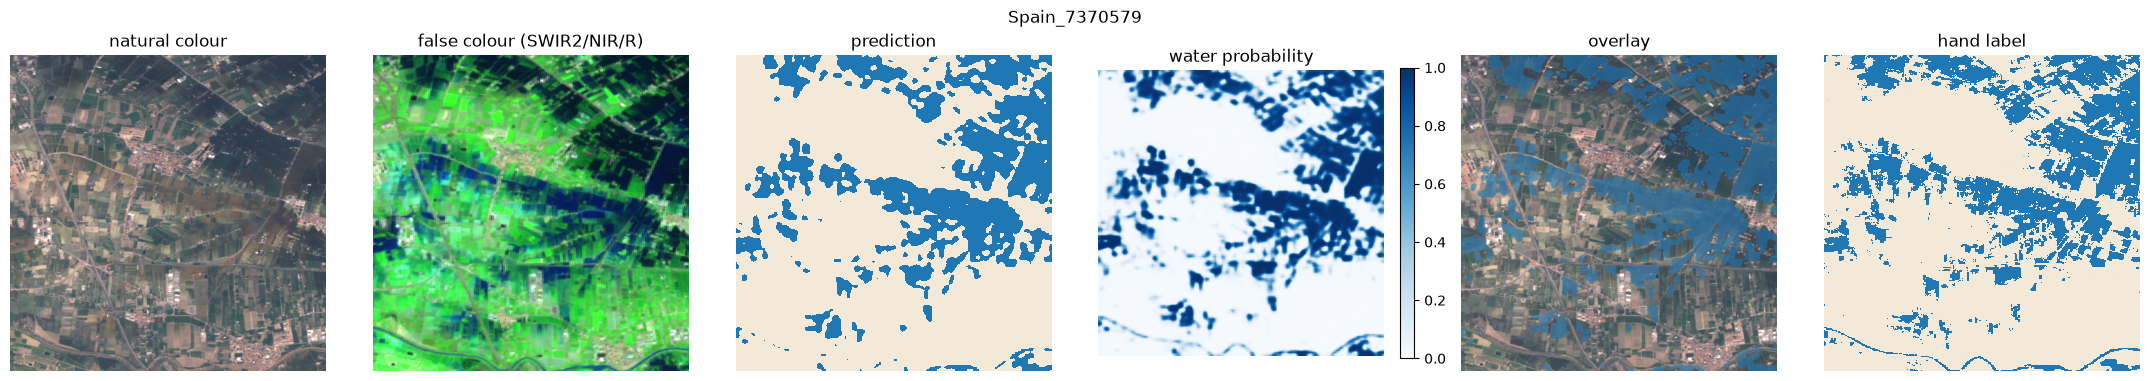

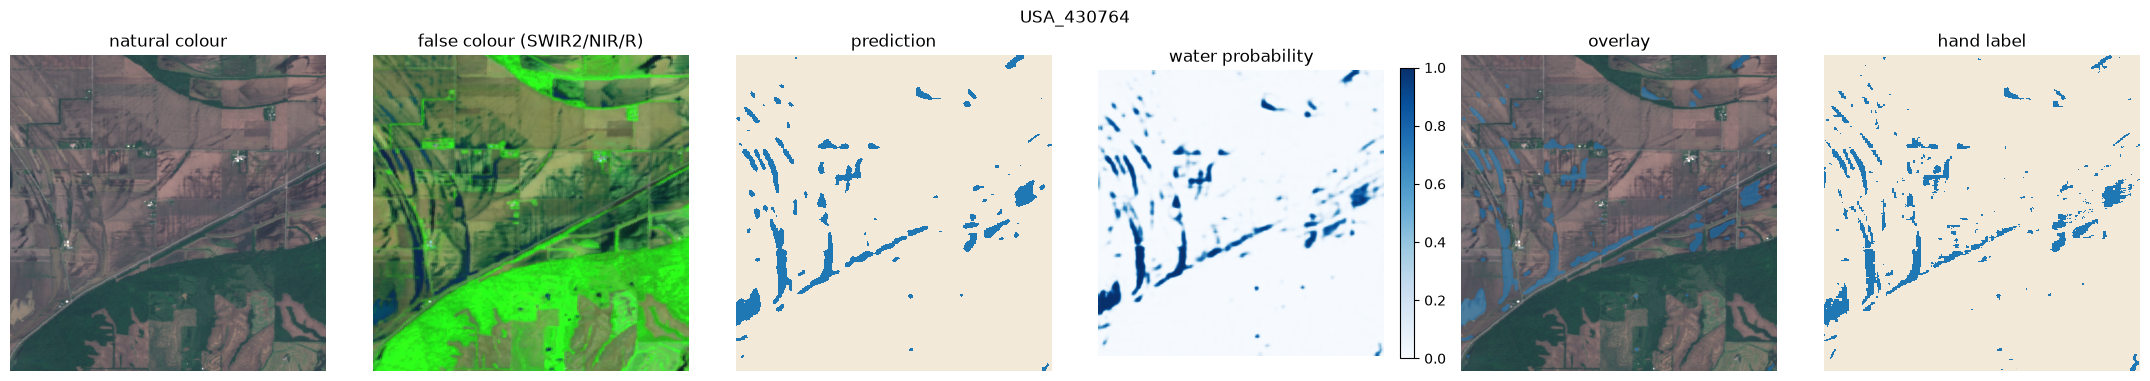

        scene |       seconds |       water % |     IoU water |          mIoU |      F1 water
 India_900498 |           6.6 |          47.0 |         0.919 |         0.923 |         0.958
Spain_7370579 |           6.2 |          27.3 |         0.725 |         0.807 |         0.841
   USA_430764 |           6.2 |           5.6 |         0.675 |         0.826 |         0.806


In [9]:
rows = []
for name in EXAMPLES:
    image, valid, profile, _ = read_s2(image_paths[name])
    t0 = time.time()
    pred, prob = predict_flood(image, valid)
    seconds = time.time() - t0
    save_geotiff(pred, OUT_DIR / f"pred_{name}.tif", profile, "uint8", NODATA_CLASS)
    label = read_label(label_paths[name]) if name in label_paths else None
    plot_result(name, image, valid, pred, prob, label)
    row = {"scene": name, "seconds": round(seconds, 1),
           "water %": round(100 * (pred == 1).sum() / max((pred != NODATA_CLASS).sum(), 1), 1)}
    if label is not None:
        row.update({k: round(v, 3) for k, v in flood_metrics(pred, label).items() if k in ("IoU water", "mIoU", "F1 water")})
    rows.append(row)

header = list(rows[0])
print(" | ".join(f"{h:>13}" for h in header))
for r in rows:
    print(" | ".join(f"{str(r.get(h, '')):>13}" for h in header))

## 10. Using your own Sentinel-2 images

- **Product level:** the model was fine-tuned on Sentinel-2 **L1C** (top-of-atmosphere) chips. For L1C files use `S2_L1C_INDICES`. For **L2A** (surface reflectance, 12 bands without B10) use `read_s2(path, S2_L2A_INDICES)`. L2A is slightly out of distribution, so check results visually.
- **Band order:** the input must be Blue, Green, Red, Narrow NIR (B8A), SWIR1, SWIR2. If your file already holds just those 6 bands, pass `band_indices=[0, 1, 2, 3, 4, 5]`.
- **Resolution:** Sen1Floods11 is at 10 m. Resample the 20 m bands (B8A, B11, B12) to 10 m first, e.g. with `gdalwarp -tr 10 10`.
- **Scaling:** digital numbers (0–10000+) are divided by 10000 automatically. Reflectance inputs that are already 0–1 are kept as they are.
- **Large scenes:** `predict_flood` tiles any size. For a full 10980×10980 tile, use a GPU and a bigger `BATCH_SIZE`.
- **Clouds:** the model has no cloud class. Thick clouds and cloud shadows can show up as false water or hide flooding, so mask them first (e.g. with the SCL layer from L2A or s2cloudless).
- **Threshold:** `predict_flood(..., threshold=0.5)` is equivalent to argmax. Raise it for fewer false alarms, lower it to catch more water.

Model card: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11. Paper: Szwarcman et al., *Prithvi-EO-2.0: A Versatile Multi-Temporal Foundation Model for Earth Observation Applications*, arXiv:2412.02732 (2024).